# Predicting Annual Revenue of Rural Water Infrastructure in Africa

## 1. Introduction

### Mission Statement
To leverage software engineering and data-driven technologies to promote transparency, accountability, and efficient public service delivery, contributing to efforts to combat corruption and strengthen good governance in Uganda and across Africa.

### Problem Statement
Rural water service providers often face challenges in estimating the revenue generated by their infrastructure, making financial planning and resource allocation difficult [1], [2]. Without reliable estimates, it becomes challenging to plan for infrastructure maintenance, operational costs, and sustainable water service delivery [3]. Using machine learning to estimate annual water-service revenue based on infrastructure characteristics, population served, and revenue collection methods could support informed decision making and financial accountability.

### Project Objectives
- Exploring and preprocessing rural water infrastructure data to identify factors influencing annual revenue.
- Developing and comparing four regression models: SGDRegressor, Linear Regression, Decision Tree, and Random Forest.
- Evaluating model performance using Mean Squared Error (MSE) and selecting the best performing model.
- Deploying the selected model through a public FastAPI service on Render, supporting predictions and retraining.
- Developing a Flutter mobile application that allows users to input infrastructure characteristics and obtain estimated annual revenue.

### Intended Users
- Water service operators
- Public infrastructure planners

### Dataset Overview
- Source: [Dryad](https://datadryad.org/dataset/doi:10.5061/dryad.7pvmcvf7r)
- Dataset Name: Revenue and investment data for rural drinking water infrastructure in Africa 2021-2024
- Author: Duncan McNicholl, University of Oxford
- Geographical coverage: 11 African countries
- Period: 2021-2024
- Observations: 11,957
- Columns: 44
- Target variable: wp_revenue_USD

### References
[1] D. McNicholl, E. Aydinsoy, and R. Hope, “Africa’s water revenue paradox,” Research Square, preprint, Mar. 2026, doi: 10.21203/rs.3.rs-8878999/v1.

[2] A. M. Armstrong, “Revenue patterns of piped water services in rural Africa,” D.Phil. dissertation, Univ. of Oxford, Oxford, U.K., 2022, doi: 10.5287/ora-2r7vvmmpb.

[3] D. S. G. Agueh, “Financing water and sanitation in Africa: Resilience, reuse, ecosystems, decentralised services and water diplomacy,” RFLD, Oct. 9, 2026. [Online]. Available: https://rflgd.org/financing-water-sanitation-africa-gloria-agueh/.


## 2. Data Loading and Initial Inspection

## 2.1 Importing libraries

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2.2 Loading dataset

In [24]:
df = pd.read_csv('data/analysis_dataset.csv')

## 2.3 Initial dataset inspection

In [25]:
print(df.shape) # Confirming dataset dimensions

df.head() # Previewing first 5 observations

df.info() # Inspecting data types and non-null counts

df.describe() # Examining numerical distributions

(11957, 44)
<class 'pandas.DataFrame'>
RangeIndex: 11957 entries, 0 to 11956
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   year                           11957 non-null  int64  
 1   lat                            11957 non-null  float64
 2   lon                            11957 non-null  float64
 3   num_taps                       11957 non-null  int64  
 4   num_hh                         11957 non-null  int64  
 5   wp_pop_last                    11957 non-null  int64  
 6   num_kiosks                     8071 non-null   float64
 7   num_scheme_tanks               3561 non-null   float64
 8   wp_revenue_model               11525 non-null  str    
 9   volume_method                  8071 non-null   str    
 10  country_name                   11957 non-null  int64  
 11  wp_m3                          11957 non-null  float64
 12  wp_revenue_USD                 11957 non-null

,year,lat,lon,num_taps,num_hh,wp_pop_last,num_kiosks,num_scheme_tanks,country_name,wp_m3,...,pop_served_last_within_2000m,pop_served_last_within_5000m,pop_served_last_within_10000m,pop_served_last_within_20000m,Population_Within_500m,Population_Within_1000m,Population_Within_2000m,Population_Within_5000m,Population_Within_10000m,Population_Within_20000m
count,11957.000000,11957.0,11957.0,11957.000000,11957.000000,11957.000000,8071.000000,3561.000000,11957.000000,11957.000000,...,11891.000000,11891.000000,11891.000000,11891.000000,11898.000000,11898.000000,11898.000000,11898.000000,1.189800e+04,1.189800e+04
mean,2022.837585,0.0,0.0,0.556410,3.582086,788.350924,0.065549,0.019938,4.405620,992.753307,...,7750.337987,20905.691111,44119.843916,79195.244302,937.563018,2226.958525,5108.264345,18034.726023,5.772356e+04,1.972405e+05
std,0.879613,0.0,0.0,2.285919,32.862670,1645.037532,1.234582,0.156851,3.419542,3051.982047,...,14058.411701,36377.288084,68471.814265,87777.140270,1470.087582,3714.054648,9035.857821,36338.479652,1.025141e+05,2.927969e+05
min,2021.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,2022.000000,0.0,0.0,0.000000,0.000000,197.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,1878.000000,8020.000000,23804.000000,192.680252,453.261508,1004.266962,3304.601272,1.104608e+04,3.589454e+04
50%,2023.000000,0.0,0.0,0.000000,0.000000,282.000000,0.000000,0.000000,3.000000,0.000000,...,2000.000000,7880.000000,22560.000000,53356.000000,451.838684,998.909635,2575.468561,10689.994140,3.172623e+04,7.608601e+04
75%,2024.000000,0.0,0.0,0.000000,0.000000,672.000000,0.000000,0.000000,9.000000,982.800000,...,7784.000000,20738.000000,47560.000000,98786.000000,1080.684444,2292.966191,5547.358155,21419.958132,6.562891e+04,2.458513e+05
max,2024.000000,0.0,0.0,44.000000,888.000000,23708.000000,44.000000,3.000000,10.000000,76673.120000,...,141960.000000,252457.000000,402122.000000,421365.000000,25361.761850,74163.978840,246267.334600,815807.769200,1.828080e+06,3.338384e+06


## 2.4 Initial observations
- The dataset contains 11,957 observations and 44 columns, covering 2021-2024.
- It includes numerical and categorical features representing rural water infrastructure.
- The target variable is wp_revenue_USD, representing annual revenue in USD.
- Some columns contain missing values that will require preprocessing.
- The latitude and longitude columns are anonymized for confidentiality.
- The twelve monthly variables contain no numerical variation.

## 3. Exploratory Data Analysis
This section investigates revenue distribution, differences between infrastructure types, relationships between variables, and potential data-quality issues that could influence the training of the model

## 3.1 Distribution of Annual Water Service Revenue

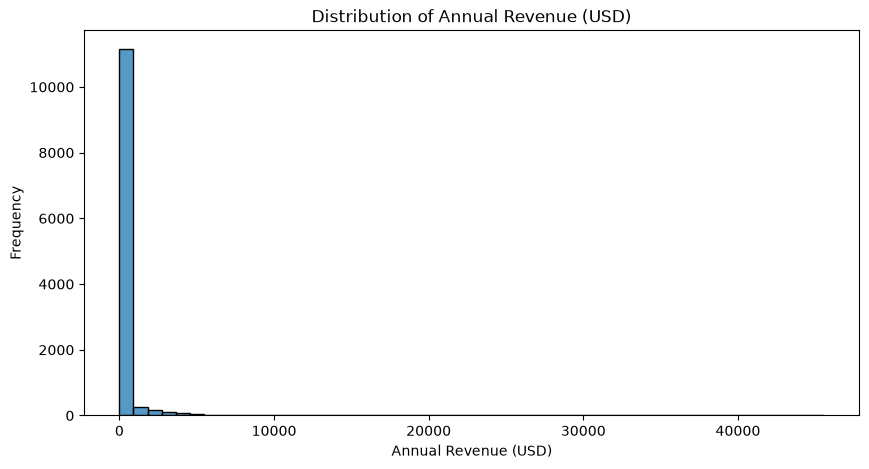

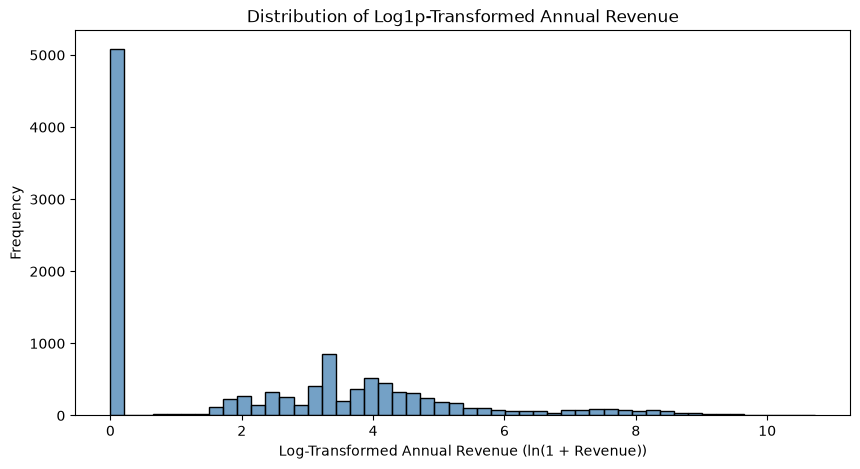

In [26]:
# Histograms comparing annual revenue distribution (USD)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="wp_revenue_USD",
    bins=50,
    kde=False
)

plt.title("Distribution of Annual Revenue (USD)")
plt.xlabel("Annual Revenue (USD)")
plt.ylabel("Frequency")
plt.show()

# Log transformed revenue histogram
# Log transformation makes it easier to see the distribution of smaller values while retaining zero revenues
log_revenue = np.log1p(df["wp_revenue_USD"])

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x=log_revenue, bins=50, kde=False, color="steelblue")

plt.title("Distribution of Log1p-Transformed Annual Revenue")
plt.xlabel("Log-Transformed Annual Revenue (ln(1 + Revenue))")
plt.ylabel("Frequency")

plt.show()

## Interpretation of revenue distribution

### Graph 1 - Distribution of Annual Revenue (USD)
### Main takeaway and modelling implications
The revenue distribution is heavily right-skewed, with most water infrastructure systems generating relatively low annual revenue. A small portion of systems generate significantly higher revenue, creating a long right tail (≈$45,562). The extreme differences in revenue could affect model performance since MSE heavily penalizes large prediction errors.

### Graph 2 - Distribution of Log1p-Transformed Annual Revenue
### Main takeaway and modelling implications
The logarithmic transformation was used to better understand the distribution through compressing large revenue values into smaller values. A prominent spike remains at zero, reflecting how 5,084 observations (42.5%) recorded no annual revenue. These zero revenue observations represent a substantial part of the dataset and should not automatically be removed.

## 3.2 Revenue Comparison by Infrastructure Type

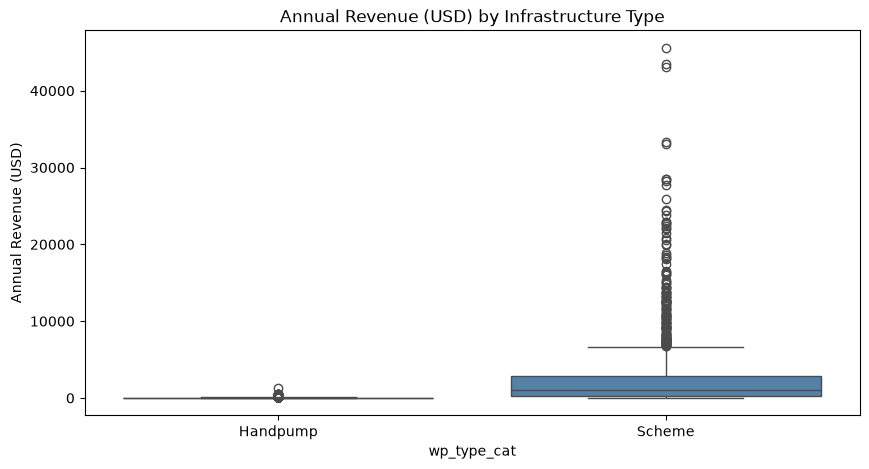

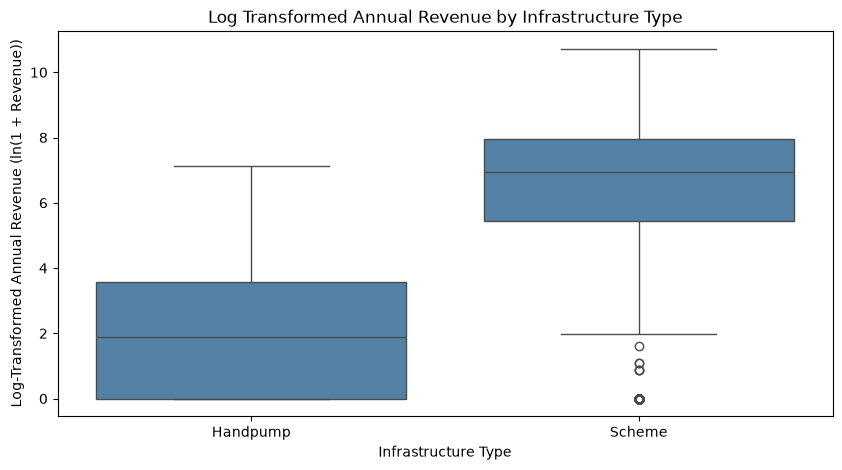

In [27]:
# Box plots comparing the revenue distributions (USD) of the two infrastructure types

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="wp_type_cat", y="wp_revenue_USD", color="steelblue")

plt.title("Annual Revenue (USD) by Infrastructure Type")
plt.ylabel("Annual Revenue (USD)")

plt.show()

# Log transformed boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="wp_type_cat", y=log_revenue, color="steelblue")

plt.title("Log Transformed Annual Revenue by Infrastructure Type")
plt.xlabel("Infrastructure Type")
plt.ylabel("Log-Transformed Annual Revenue (ln(1 + Revenue))")

plt.show()

## Interpretation of boxplots

### Graph 1 - Distribution of Annual Revenue (USD) by Infrastructure Type
### Main takeaway and modelling implications
Water schemes generate significantly higher annual revenue than handpumps. Schemes also have a greater spread in revenue with several outliers reaching ≈$45,562. The difference in revenue scale indicates that infrastructure type (wp_type_cat) is an important variable to consider when predicting annual revenue.


### Graph 2 - Distribution of Log1p-Transformed Annual Revenue by Infrastructure Type
### Main takeaway and modelling implications
Water schemes have a noticeably higher median revenue (**\$1,028**) than hand pumps (**\$5.57**). The lower quartile of handpump revenue is zero, reflecting a significant number of handpumps that generate no revenue. The observation encourages the evaluation of model performance separately for handpumps and schemes, since overall MSE may be dominated by the much larger scheme revenue, if handled together.


## 3.3 Correlation Heatmap

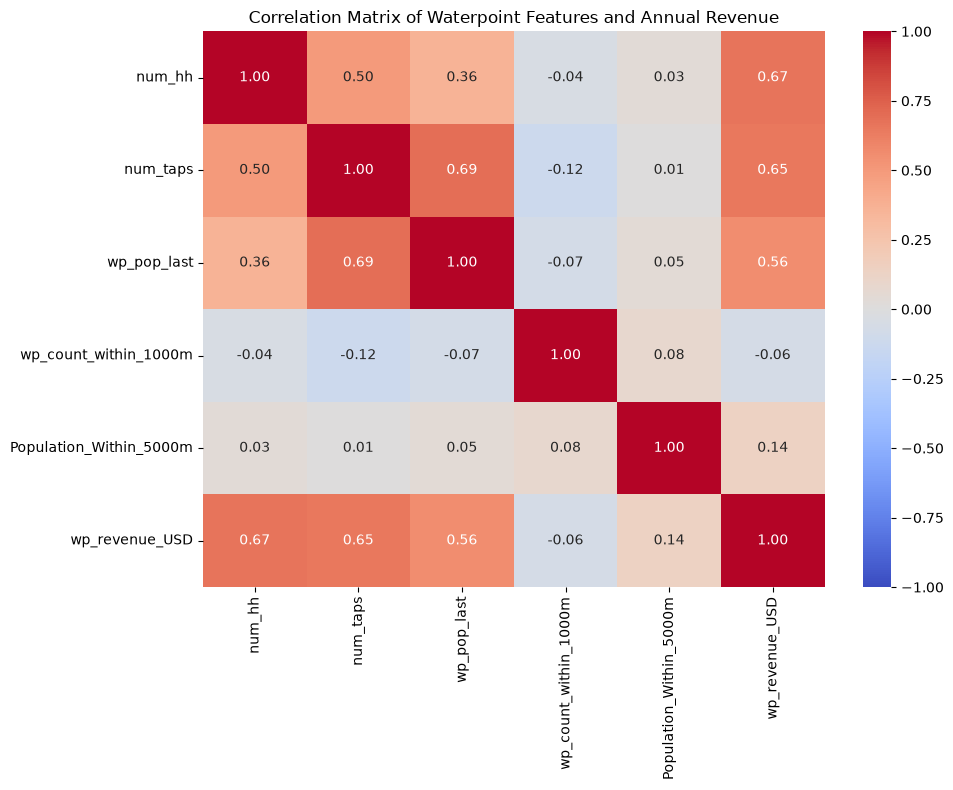

In [28]:
# Correlation heatmap of numerical predictors and the revenue target

cols = [
    "num_hh",
    "num_taps",
    "wp_pop_last",
    "wp_count_within_1000m",
    "Population_Within_5000m",
    "wp_revenue_USD",
]

# Calculation of the correlation matrix
corr_matrix = df[cols].corr()

# Plotting the heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,  # Display correlation values inside each cell
    fmt=".2f",  # Round numbers to 2 decimal places for readability
    cmap="coolwarm",  # Diverging color scheme (blue = negative, red = positive)
    vmin=-1,  # Anchor color scale minimum at -1
    vmax=1,  # Anchor color scale maximum at 1
    center=0,  # Set neutral color midpoint at 0
)

plt.title("Correlation Matrix of Waterpoint Features and Annual Revenue")
plt.tight_layout()

plt.show()

## Interpretation of correlation map
The number of households (num_hh), number of taps (num_taps), and population served (wp_pop_last) show the strongest positive relationships with annual revenue. This suggests that larger water supply systems serving more households and people tend to generate higher revenue, and that more taps tend to serve larger populations indicating potential multicollinearity. Households, taps, and population served are promising numerical predictors, whereas the weaker predictors shall initially be retained because they may capture nonlinear relationships that Decision Tree and Random Forest models can exploit.

## 3.4 Scatterplot (Before Model Training)

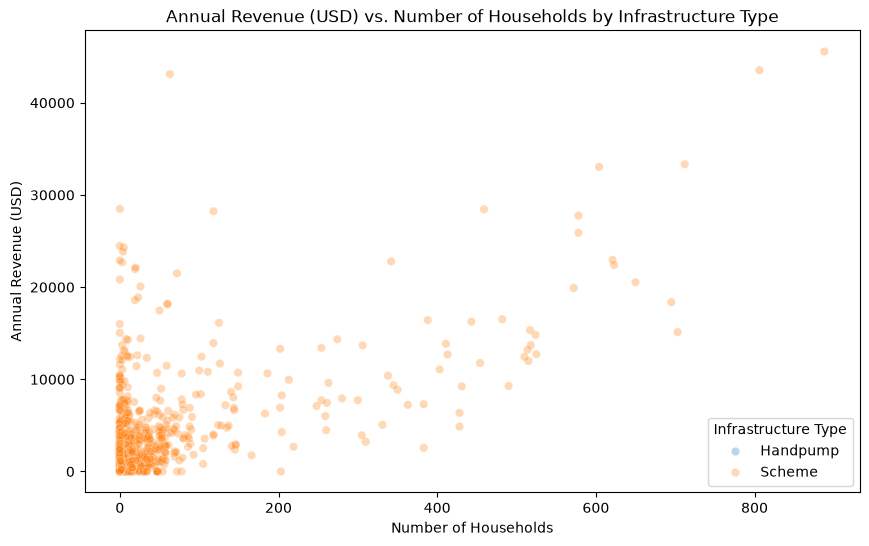

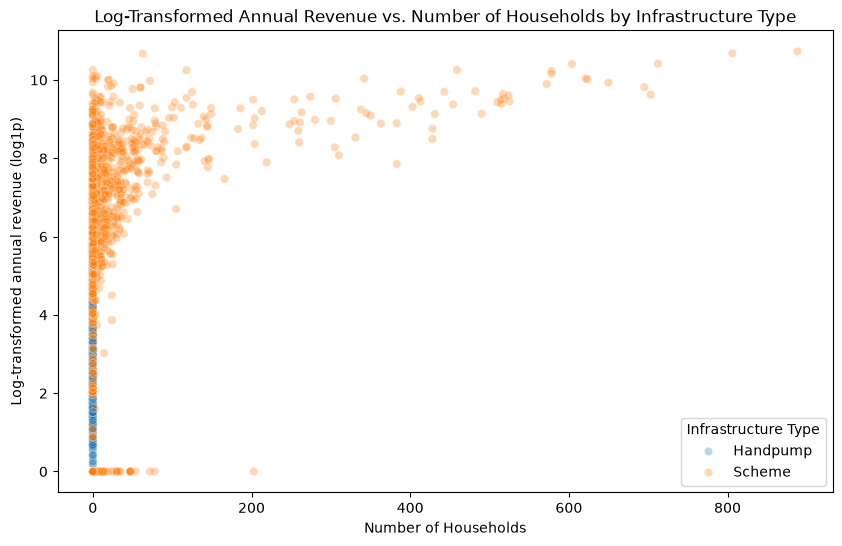

In [29]:
# Scatterplot of the most strongly correlated eligible numerical predictors against revenue

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="num_hh", y="wp_revenue_USD", hue="wp_type_cat", alpha=0.3)

plt.title("Annual Revenue (USD) vs. Number of Households by Infrastructure Type")
plt.xlabel("Number of Households")
plt.ylabel("Annual Revenue (USD)")
plt.legend(title="Infrastructure Type")

plt.show()

# Log transformed scatter plot

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="num_hh", y=log_revenue, hue="wp_type_cat", alpha=0.3)

plt.title("Log-Transformed Annual Revenue vs. Number of Households by Infrastructure Type")
plt.xlabel("Number of Households")
plt.ylabel("Log-transformed annual revenue (log1p)")
plt.legend(title="Infrastructure Type")

plt.show()



## Interpretation of scatter plot (before training)
The plot shows a general positive relationship between the number of households and annual revenue. Handpump observations remain concentrated at low household counts and revenue levels, while schemes are more widely spread across higher household counts and higher revenues. Many observations are clustered at very low household counts, especially near zero, which suggests that the dataset contains many small-scale systems, and that the relationship between households and revenue is not perfectly linear across the full range.

## 4 Data Preparation and Feature Selection

### 4.1 Feature Selection

In [30]:
# Definition of the eight selected predictor columns
predictors = [
    'wp_type_cat',
    'wp_revenue_model',
    'volume_method',
    'num_hh',
    'num_taps',
    'wp_pop_last',
    'wp_count_within_1000m',
    'Population_Within_5000m'
]

# Definition of the target variable separately
target = 'wp_revenue_USD'

# Creation of new dataframe only containing the nine columns
model_df = df[predictors + [target]].copy()

# Shape and column verification of the new data
print("New DataFrame shape:", model_df.shape)
model_df.head()

New DataFrame shape: (11957, 9)


,wp_type_cat,wp_revenue_model,volume_method,num_hh,num_taps,wp_pop_last,wp_count_within_1000m,Population_Within_5000m,wp_revenue_USD
0,Handpump,waterpoint,estimated,0,0,540,2,16765.475450,0.00
1,Handpump,waterpoint,NaN,0,0,275,0,6819.277203,105.84
2,Handpump,waterpoint,NaN,0,0,185,0,3808.431144,227.53
3,Handpump,waterpoint,NaN,0,0,200,0,5872.281555,12.96
4,Handpump,waterpoint,NaN,0,0,180,0,11283.372050,92.74


## Justification of feature exclusions

| Excluded columns | Reason |
| :--- | :--- |
| lat, lon | Anonymized placeholders (privacy/contractual reasons) |
| month_1 – month_12 | All non-missing values are zero |
| num_scheme_tanks | Approximately 70% missing |
| num_kiosks | Significant missingness and not essential to the model |
| wp_m3 | Uncertain whether actual water volume is available at prediction time |
| country_name | Encoded country labels without a verified mapping for app users |
| quarters_used | Unclear reporting-period information |
| year | The model estimates revenue from infrastructure types rather than forecasting future years |
| other population and waterpoint radius columns | Risk of introducing redundant information and calculations |

## 4.2 Missing value handling

In [31]:
# Calculating missing value counts per column
missing_count = model_df.isna().sum()

# Calculating percentage of missing values
missing_percent = (missing_count / len(model_df)) * 100

# Combining into a three-column summary table
missing_summary = pd.DataFrame({
    'Column': model_df.columns,
    'Missing Count': missing_count.values,
    'Missing Percentage (%)': missing_percent.values.round(2)
})

# Sorting the table from highest to lowest in terms of missingness
missing_summary = missing_summary.sort_values(by='Missing Count', ascending=False).reset_index(drop=True)
display(missing_summary)

,Column,Missing Count,Missing Percentage (%)
0,volume_method,3886,32.50
1,wp_revenue_model,432,3.61
2,Population_Within_5000m,59,0.49
3,wp_type_cat,0,0.00
4,num_hh,0,0.00
5,num_taps,0,0.00
6,wp_pop_last,0,0.00
7,wp_count_within_1000m,0,0.00
8,wp_revenue_USD,0,0.00


## Missing value handling strategy

| Feature | Handling strategy | Justification |
| :--- | :--- | :--- |
| wp_revenue_model | Replacing missing values with Unknown | Avoids assuming a particular payment model |
| volume_method | Replacing missing values with Unknown | Preserves observations without assuming a measurement method |
| Population_Within_5000m | Median imputation | Very few missing values; median less sensitive to extreme values |

## Interpretation of missing value handling
- Only three of the eight selected predictors contain missing values
- volume_method has the highest missingness at 32.5%, so dropping incomplete rows would result in significant data loss
- Using an unknown category for categorical values and median imputation for numerical values allows more observations to be retained without making unnecessary assumptions

## 4.3 Definition of predictors and target

In [32]:
# Assigning the eight predictor columns to X (DataFrame)
X = model_df[predictors]

# Assigning the single target column to y (Series)
y = model_df[target]

# Defining the list of the five numerical feature names
numerical_features = [
    'num_hh',
    'num_taps',
    'wp_pop_last',
    'wp_count_within_1000m',
    'Population_Within_5000m'
]

# Defining the list of the three categorical feature names
categorical_features = [
    'wp_type_cat',
    'wp_revenue_model',
    'volume_method'
]


# Shape verification
print("X shape:", X.shape)
print("y shape:", y.shape)

# Verifying that all 8 predictors are accounted for
assert len(numerical_features) + len(categorical_features) == len(predictors), "Feature count mismatch!"
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

X shape: (11957, 8)
y shape: (11957,)
Numerical features: 5
Categorical features: 3


## Interpretation of the feature separation
The features were separated into numerical and categorical categories since different data types require different preprocessing operations (Categories like "Handpump" cannot be standardized the same way as a numerical value like 500 people)

## 4.4 Train-test split

In [33]:
from sklearn.model_selection import train_test_split

# Splitting X and y into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Calculating normalized proportions for wp_type_cat in both sets
train_props = X_train['wp_type_cat'].value_counts(normalize=True) * 100
test_props = X_test['wp_type_cat'].value_counts(normalize=True) * 100

# Displaying comparison table
distribution_check = pd.DataFrame({
    'Train Set (%)': train_props.round(2),
    'Test Set (%)': test_props.round(2)
})

# Verifying the shapes of the resulting splits
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
display(distribution_check)

X_train shape: (9565, 8)
X_test shape: (2392, 8)
y_train shape: (9565,)
y_test shape: (2392,)


,Train Set (%),Test Set (%)
wp_type_cat,,
Handpump,87.08,88.0
Scheme,12.92,12.0


## Main takeaways from the train-test splitting
- The dataset was divided into an 80/20 split, with 9,565 training observations and 2,392 testing observations
- Both subsets contain similar proportions of handpumps and schemes, with handpumps accounting for approximately 87-88% of observations
- The similar proportions indicate that both infrastructure types are represented consistently across the training and testing sets

## 4.5 Preprocessing pipeline

In [34]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Filling missing numerical values using the median of the corresponding training column and carrying out standardization
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Filling missing categorical output with Unknown and using one-hot encoding to convert categories into binary numerical columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combining the two pipelines using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit on training data and transforming it
X_train_processed = preprocessor.fit_transform(X_train)

# Transforming testing data using parameters learned from X_train
X_test_processed = preprocessor.transform(X_test)

# Verifying that zero missing values remain in both transformed arrays
train_missing = np.isnan(X_train_processed).sum()
test_missing = np.isnan(X_test_processed).sum()

# Inspecting the transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Verifying the shapes of the processed arrays
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)
print("Missing values in X_train_processed:", train_missing)
print("Missing values in X_test_processed:", test_missing)
print("\nTotal transformed features:", len(feature_names))
print("Feature names:\n", feature_names)

X_train_processed shape: (9565, 15)
X_test_processed shape: (2392, 15)
Missing values in X_train_processed: 0
Missing values in X_test_processed: 0

Total transformed features: 15
Feature names:
 ['num__num_hh' 'num__num_taps' 'num__wp_pop_last'
 'num__wp_count_within_1000m' 'num__Population_Within_5000m'
 'cat__wp_type_cat_Handpump' 'cat__wp_type_cat_Scheme'
 'cat__wp_revenue_model_Unknown' 'cat__wp_revenue_model_volumetric'
 'cat__wp_revenue_model_waterpoint' 'cat__volume_method_Unknown'
 'cat__volume_method_automated' 'cat__volume_method_estimated'
 'cat__volume_method_manual' 'cat__volume_method_unmeasured']


## Key takeaways from preprocessing pipeline
- The preprocessing pipeline successfully converted the eight original predictors into 15 numerical features through standardization and one-hot encoding
- Missing values were successfully handled without removing observations, resulting in no missing values either in the processed training or testing dataset
- The preprocessing components were fitted exclusively on the training data and then applied to the test data, ensuring consistent transformations.

## 5. Linear Regression Using SGDRegressor

## 5.1 Understanding SGDRegressor and establishing a baseline

In [35]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Starting settings
sgd_baseline = SGDRegressor(
    loss="squared_error",       # loss function being minimized
    penalty="l2",               # regularization of model weights
    alpha=0.0001,               # Strengthening of regularization
    learning_rate="constant",   # Keeping the learning rate fixed
    eta0=0.001,                 # Initial learning rate
    max_iter=1000,              # Maximum number of epochs
    random_state=42,             # Reproducibility
)

# Fitting the model on the processed training data
sgd_baseline.fit(X_train_processed, y_train)

# Generating predictions on both training and testing sets
train_preds = sgd_baseline.predict(X_train_processed)
test_preds = sgd_baseline.predict(X_test_processed)

# Calculating evaluation metrics
train_mse = mean_squared_error(y_train, train_preds)
test_mse = mean_squared_error(y_test, test_preds)
test_mae = mean_absolute_error(y_test, test_preds)
test_r2 = r2_score(y_test, test_preds)

# Displaying results in table
results_df = pd.DataFrame({
    "Metric": ["Train MSE", "Test MSE", "Test MAE", "Test R²"],
    "Result": [train_mse, test_mse, test_mae, test_r2],
})

print(results_df.to_string(index=False))

   Metric       Result
Train MSE 1.318617e+06
 Test MSE 8.424066e+05
 Test MAE 2.978413e+02
  Test R² 7.321318e-01


## Takeaways from SGDRegressor and baseline establishment
- The initial SGDRegressor model achieved a test R² of approximately 0.73, indicating that it captures a significant proportion of the variation in annual water-service revenue
- The test MAE of approximately (**\$297**) and the higher RMSE of approximately (**\$918**) suggest that some observations have large prediction errors, potentially related to the skewed revenue distribution
- The baseline establishes a reference point for investigating whether adjustments to learning rate, regularization strength, and training epochs improve model performance 

## 5.2 Hyperparameter experimentation

## 5.2.1 Creation of validation subset

In [36]:
from sklearn.base import clone

# Splitting the raw training data into tuning-train (80%) and validation (20%) sets
X_tune_train, X_val, y_tune_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
)

# Creation of an unfitted copy of the existing preprocessor
tuning_preprocessor = clone(preprocessor)

# Fitting and transforming the tuning training set
X_tune_train_processed = tuning_preprocessor.fit_transform(X_tune_train)

# Transforming the validation set using the fitted tuning preprocessor
X_val_processed = tuning_preprocessor.transform(X_val)

# Verifying the shapes
print(f"X_tune_train: {X_tune_train.shape}")
print(f"X_val:        {X_val.shape}")
print(f"y_tune_train: {y_tune_train.shape}")
print(f"y_val:        {y_val.shape}")
print(f"X_tune_train_processed: {X_tune_train_processed.shape}")
print(f"X_val_processed:        {X_val_processed.shape}")


X_tune_train: (7652, 8)
X_val:        (1913, 8)
y_tune_train: (7652,)
y_val:        (1913,)
X_tune_train_processed: (7652, 15)
X_val_processed:        (1913, 15)


## 5.2.2 Experimenting with learning rates

In [37]:
# Candidate learning rates to test
learning_rates = [0.00001, 0.0001, 0.001, 0.01]
lr_n_epochs = 50

# Dictionaries to store epoch-by-epoch history and final summary results
history = {}
lr_results = []

for lr in learning_rates:
    # Initializing the model once outside the epoch loop so the weight carries over
    model = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        alpha=0.0001,
        learning_rate="constant",
        eta0=lr,
        random_state=42,
    )

    lr_train_mse_history = []
    lr_val_mse_history = []

    # Looping through 50 epochs using partial_fit()
    for epoch in range(lr_n_epochs):
        model.partial_fit(X_tune_train_processed, y_tune_train)

        # Predicting and recording MSE after each epoch
        train_preds = model.predict(X_tune_train_processed)
        val_preds = model.predict(X_val_processed)

        lr_train_mse_history.append(mean_squared_error(y_tune_train, train_preds))
        lr_val_mse_history.append(mean_squared_error(y_val, val_preds))

    # Saving full learning curves for plotting later
    history[lr] = {
        "train_mse": lr_train_mse_history,
        "val_mse": lr_val_mse_history,
    }

    # Recording the final epoch metrics for comparison
    lr_results.append({
        "eta0": lr,
        "Final Train MSE (Epoch 50)": lr_train_mse_history[-1],
        "Final Val MSE (Epoch 50)": lr_val_mse_history[-1],
        "Best Val MSE": min(lr_val_mse_history),
    })

# Displaying the summary comparison table
lr_results_df = pd.DataFrame(lr_results)
print(lr_results_df.to_string(index=False))

   eta0  Final Train MSE (Epoch 50)  Final Val MSE (Epoch 50)  Best Val MSE
0.00001                1.455526e+06              9.231587e+05  9.231587e+05
0.00010                1.424385e+06              8.816929e+05  8.816929e+05
0.00100                1.531803e+06              8.838751e+05  8.838718e+05
0.01000                4.820075e+06              4.317342e+06  3.204690e+06


## Key takeaways from the experimentation with learning rates
- The smallest learning rate (0.00001) produced relatively higher validation loss, suggesting slower convergence within the 50-epoch training budget
- The learning rate of 0.0001 achieved the lowest validation MSE, providing the best observed balance between convergence and stability
- Increasing the learning rate to 0.01 significantly increased both training and validation loss, suggesting that excessively large weight updates negatively affected convergence

## 5.2.3 Experimenting with regularization strengths

In [38]:
alpha_values = [0.00001, 0.0001, 0.001, 0.01, 0.1]
alpha_n_epochs = 50

alpha_history = {}
alpha_results = []

for alpha in alpha_values:
    model = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        alpha=alpha,
        learning_rate="constant",
        eta0=0.0001,
        random_state=42,
    )
    
    alpha_train_mse_list = []
    alpha_val_mse_list = []

    for epoch in range(alpha_n_epochs):
        model.partial_fit(X_tune_train_processed, y_tune_train)

        # Generating predictions
        train_preds = model.predict(X_tune_train_processed)
        val_preds =  model.predict(X_val_processed)

        # Calculating and storing the mse
        train_mse = mean_squared_error(y_tune_train, train_preds)
        val_mse = mean_squared_error(y_val, val_preds)

        alpha_train_mse_list.append(train_mse)
        alpha_val_mse_list.append(val_mse)

    # Storing full epoch history
    alpha_history[alpha] = {"train_mse": alpha_train_mse_list, "val_mse": alpha_val_mse_list}

    # Appending only the final summary row
    alpha_results.append({
        "alpha": alpha,
        "Final Train MSE (Epoch 50)": alpha_train_mse_list[-1],
        "Final Val MSE (Epoch 50)": alpha_val_mse_list[-1],
        "Best Val MSE": min(alpha_val_mse_list),
    })

# Converting summary results into a dataframe
alpha_results_df = pd.DataFrame(alpha_results)
display(alpha_results_df)


,alpha,Final Train MSE (Epoch 50),Final Val MSE (Epoch 50),Best Val MSE
0,0.00001,1.424347e+06,881671.830882,881671.830882
1,0.00010,1.424385e+06,881692.900558,881692.900558
2,0.00100,1.424765e+06,881904.296760,881904.296760
3,0.01000,1.428535e+06,884053.810460,884053.810460
4,0.10000,1.457650e+06,901166.491483,901166.491483


## Key takeaways from the experimentation with regularization strengths
- Five regularization strengths were evaluated while keeping the learning rate fixed at 0.0001 and training each model for 50 epochs
- The smallest alpha value, 0.00001, produced the lowest validation MSE, while stronger regularization gradually increased both training and validation loss
- This suggests that weak regularization is more suitable for our current model, although its improvement over the baseline regularization strength is minimal

## 5.2.4 Experimenting with training epochs

In [39]:
selected_lr = 0.0001
selected_alpha = 0.00001
max_epochs = 500
checkpoint_epochs = [10, 50, 100, 200, 500]

# Model initialization
model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=selected_alpha,
    learning_rate="constant",
    eta0=selected_lr,
    random_state=42
)

epoch_train_mse_list = []
epoch_val_mse_list = []

for epoch in range(max_epochs):
    model.partial_fit(X_tune_train_processed, y_tune_train)

    # Generating predictions
    train_preds = model.predict(X_tune_train_processed)
    val_preds = model.predict(X_val_processed)

    # Calculating and storing MSE
    train_mse = mean_squared_error(y_tune_train, train_preds)
    val_mse = mean_squared_error(y_val, val_preds)

    epoch_train_mse_list.append(train_mse)
    epoch_val_mse_list.append(val_mse)

# Extracting results at the five milestone epochs using zero-based indexing
epoch_results = []

for ep in checkpoint_epochs:
    idx = ep - 1 # Epoch 10 -> index 9
    epoch_results.append({
    "Epochs": ep,
    "Train MSE": epoch_train_mse_list[idx],
    "Val MSE": epoch_val_mse_list[idx],
    "Best Val MSE So Far": min(epoch_val_mse_list[: ep]),
})

# Displaying the summary DataFrame
epoch_results_df = pd.DataFrame(epoch_results)
display(epoch_results_df)

,Epochs,Train MSE,Val MSE,Best Val MSE So Far
0,10,1.448405e+06,903477.199219,903477.199219
1,50,1.424347e+06,881671.830882,881671.830882
2,100,1.412183e+06,871856.112571,871856.112571
3,200,1.400710e+06,863160.329630,863160.329630
4,500,1.394272e+06,860145.641418,860068.414236


## 5.3 Plotting and interpreting the training and validation MSE curves

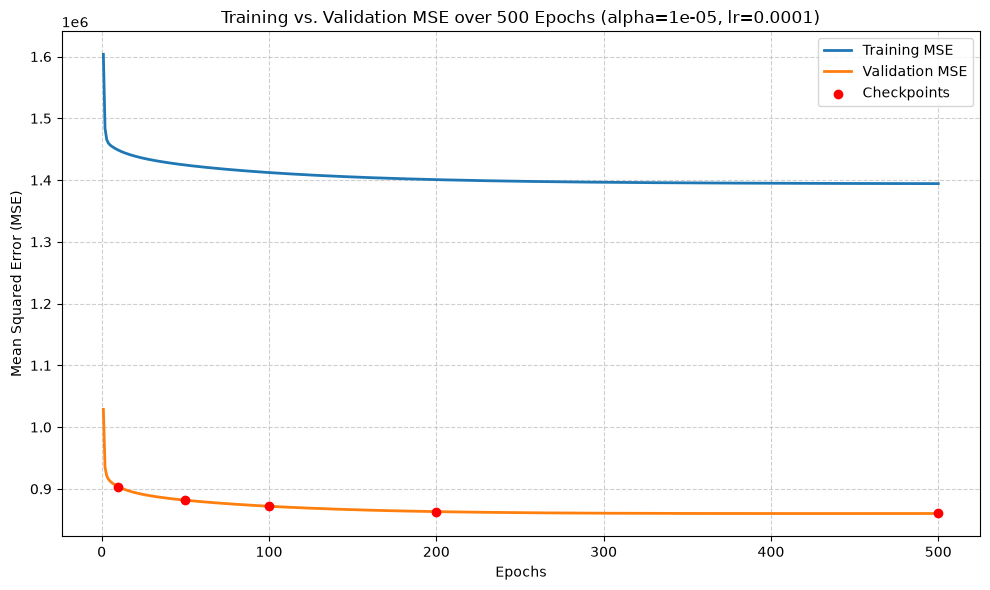

In [40]:
epochs_range = range(1, max_epochs + 1)

plt.figure(figsize=(10, 6))

plt.plot(epochs_range, epoch_train_mse_list, label="Training MSE", linewidth=2)
plt.plot(epochs_range, epoch_val_mse_list, label="Validation MSE", linewidth=2)

# Checkpoint highlighting
checkpoint_epochs = [10, 50, 100, 200, 500]
checkpoint_val_mse = [epoch_val_mse_list[ep - 1] for ep in checkpoint_epochs]

plt.scatter(
    checkpoint_epochs,
    checkpoint_val_mse,
    color="red",
    zorder=5,
    label="Checkpoints",
)

plt.title(
    f"Training vs. Validation MSE over {max_epochs} Epochs (alpha={selected_alpha},"
    f" lr={selected_lr})"
)
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## Interpretation of the loss curves
- Both training and validation loss decrease sharply during the first few epochs, indicating that the model quickly learns useful relationships between predictors and revenue
- After the initial decrease, both curves continue declining at a slower rate and begin to flatten, particularly after approximately 200 epochs
- Increasing the number of epochs from 200 to 500 produces only a small improvement in validation MSE
- Both losses decrease together without a sustained increase in validation loss while training loss decreases

## 5.4 Final Optimized SGDRegressor Training

## 5.4.1 Initializing and training the final model with partial_fit()

In [41]:
selected_lr = 0.0001
selected_alpha = 0.00001
final_n_epochs = 500

# Initializing fresh SGDRegressor for the full training dataset
final_sgd_model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=selected_alpha,
    learning_rate="constant",
    eta0=selected_lr,
    random_state=42,
)

# Tracking MSE across epochs
final_train_mse_history= []
final_test_mse_history = []
for epoch in range(final_n_epochs):
    final_sgd_model.partial_fit(X_train_processed, y_train)

    # Generating training and test predictions
    sgd_train_preds = final_sgd_model.predict(X_train_processed)
    sgd_test_preds = final_sgd_model.predict(X_test_processed)

    # Calculating training and test MSE
    sgd_train_mse = mean_squared_error(y_train, sgd_train_preds)
    sgd_test_mse = mean_squared_error(y_test, sgd_test_preds)

    # Storing history
    final_train_mse_history.append(sgd_train_mse)
    final_test_mse_history.append(sgd_test_mse)

# Final epoch MSE values
print(f"Final Train MSE (Epoch 500): {final_train_mse_history[-1]:,.2f}")
print(f"Final Test MSE (Epoch 500):  {final_test_mse_history[-1]:,.2f}")


Final Train MSE (Epoch 500): 1,291,427.05
Final Test MSE (Epoch 500):  744,180.16


## 5.4.2 Final training and testing loss curves

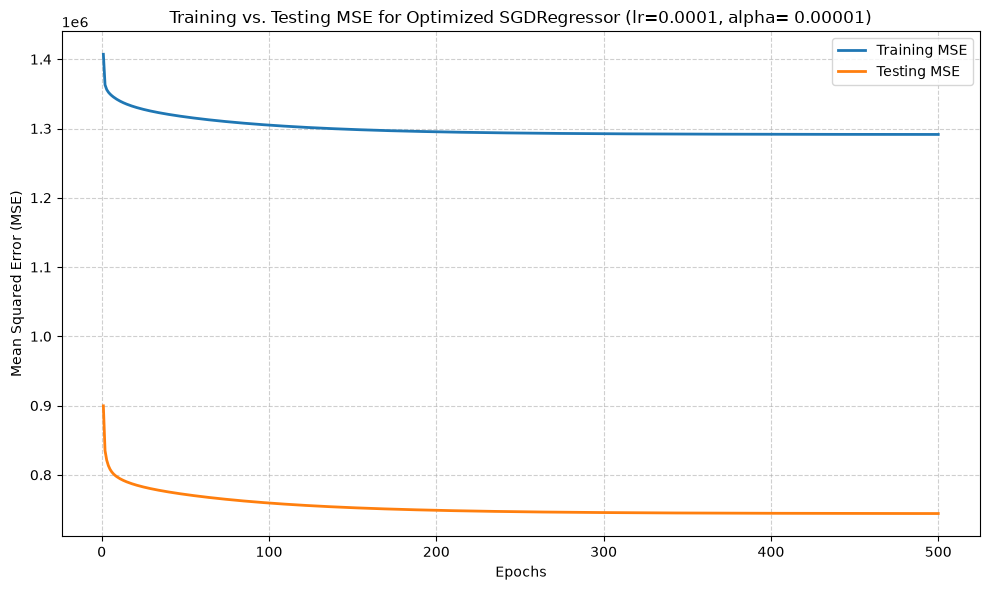

In [42]:
# x-axis ranging from epoch 1 to the final training epoch
epochs_range = range(1, final_n_epochs + 1)

plt.figure(figsize=(10, 6))

# Plotting both final loss histories
plt.plot(
    epochs_range, final_train_mse_history, label="Training MSE", linewidth=2
)
plt.plot(epochs_range, final_test_mse_history, label="Testing MSE", linewidth=2)

plt.title(
    "Training vs. Testing MSE for Optimized SGDRegressor (lr=0.0001,"
    " alpha= 0.00001)"
)
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## Interpretation of loss curve results
- Both training and testing losses decreased and gradually stabilized, indicating that the model approached convergence
- The optimized model achieved a lower test MSE than the baseline, demonstrating improved predictive performance following hyperparameter tuning
- There is no obvious evidence of overfitting in the loss curves, although the lower test loss may reflect differences in the revenue distributions between the two datasets

In [43]:
# Generating and preserving predictions from the optimized SGD model
sgd_train_preds = final_sgd_model.predict(X_train_processed)
sgd_test_preds = final_sgd_model.predict(X_test_processed)

# Reusing final MSE values from Epoch 500
final_train_mse = final_train_mse_history[-1]
final_test_mse = final_test_mse_history[-1]

# Calculating additional evaluation metrics
final_test_rmse = np.sqrt(final_test_mse)
final_test_mae = mean_absolute_error(y_test, sgd_test_preds)
final_test_r2 = r2_score(y_test, sgd_test_preds)

# Calculating negative prediction count and percentage
negative_preds_count = int(np.sum(sgd_test_preds < 0))
negative_preds_pct = (negative_preds_count / len(y_test)) * 100

# Storing metrics for final model comparison
sgd_final_metrics = {
    "Model": "Optimized SGDRegressor",
    "Train MSE": final_train_mse,
    "Test MSE": final_test_mse,
    "Test RMSE": final_test_rmse,
    "Test MAE": final_test_mae,
    "Test R²": final_test_r2,
    "Negative Predictions": negative_preds_count,
    "Negative Predictions (%)": negative_preds_pct,
}

# Converting metrics into a DataFrame
sgd_results_df = pd.DataFrame([sgd_final_metrics])
display(sgd_results_df)

,Model,Train MSE,Test MSE,Test RMSE,Test MAE,Test R²,Negative Predictions,Negative Predictions (%)
0,Optimized SGDRegressor,1.291427e+06,744180.157984,862.658773,295.583493,0.763366,1264,52.842809
